# Task 50: Tuning and Generalization Comparison

Compare baseline and manually tuned models using cross-validation, held-out metrics, train-validation gaps, and development-only convergence curves.

Manual CV tuning results:


,Model,Setting,Mean CV F1,Fold F1 SD
0,Logistic regression,"(0.06, 700, 0.02)",0.844,0.060
1,Logistic regression,"(0.03, 1000, 0.001)",0.846,0.058
2,Decision stump,"(1,)",0.798,0.027
3,Decision stump,"(1,)",0.798,0.027
4,k-NN,"(5,)",0.858,0.065
5,k-NN,"(9,)",0.842,0.036


Before/after held-out results:


Train accuracy  Test accuracy  \
Model               Phase                                          
Logistic regression Before tuning           0.830          0.820   
                    After tuning            0.830          0.820   
Decision stump      Before tuning           0.780          0.672   
                    After tuning            0.780          0.672   
k-NN                Before tuning           0.876          0.803   
                    After tuning            0.876          0.803   

                                   Accuracy gap  Test precision  Test recall  \
Model               Phase                                                      
Logistic regression Before tuning         0.010           0.844        0.818   
                    After tuning          0.010           0.844        0.818   
Decision stump      Before tuning         0.108           0.741        0.606   
                    After tuning          0.108           0.741        0.606   
k-NN                Before tuning         0.072           0.839        0.788   
                    After tuning          0.072           0.839        0.788   

                                   Test f1  
Model               Phase                   
Logistic regression Before tuning    0.831  
                    After tuning     0.831  
Decision stump      Before tuning    0.667  
                    After tuning     0.667  
k-NN                Before tuning    0.812  
                    After tuning     0.812

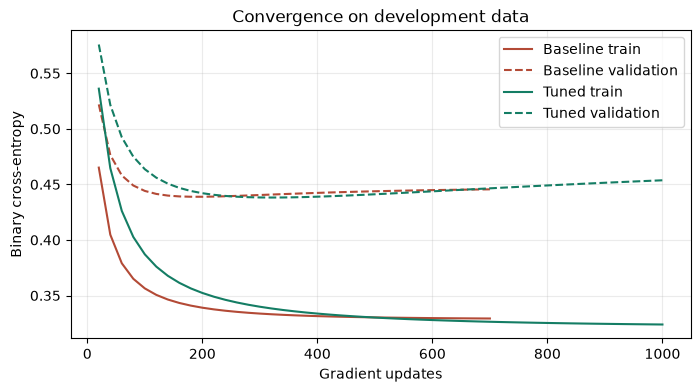

A small CV score gain with lower fold SD is preferable to a single noisy test improvement; a large train/test accuracy gap suggests overfitting.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

paths=[Path('heart.csv'),Path('Task_50_Tuning_Generalization_Comparison/heart.csv'),Path('Heart_Disease_Tasks/Task_50_Tuning_Generalization_Comparison/heart.csv')]
data=pd.read_csv(next(p for p in paths if p.is_file())).drop_duplicates().reset_index(drop=True)
features=[c for c in ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal'] if c in data]
X,y=data[features].to_numpy(float),data.target.to_numpy(int)

def stratified_split(labels,fraction,seed):
    rng=np.random.default_rng(seed);a=[];b=[]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids);cut=round(fraction*len(ids));a.extend(ids[:cut]);b.extend(ids[cut:])
    rng.shuffle(a);rng.shuffle(b);return np.array(a),np.array(b)
trainval,test=stratified_split(y,.8,50);Xdev,Xtest=X[trainval],X[test];ydev,ytest=y[trainval],y[test]

def make_folds(labels,count=3,seed=50):
    rng=np.random.default_rng(seed);folds=[[] for _ in range(count)]
    for label in np.unique(labels):
        ids=np.flatnonzero(labels==label);rng.shuffle(ids)
        for i,part in enumerate(np.array_split(ids,count)):folds[i].extend(part.tolist())
    return [np.array(sorted(f)) for f in folds]
folds=make_folds(ydev)

class ManualLogistic:
    def __init__(self,rate=.06,steps=700,l2=.02):self.rate,self.steps,self.l2=rate,steps,l2
    def fit(self,x,y):
        self.w=np.zeros(x.shape[1]);self.b=0.
        for _ in range(self.steps):
            p=1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)));e=p-y
            self.w-=self.rate*(x.T@e/len(y)+self.l2*self.w);self.b-=self.rate*e.mean()
        return self
    def predict(self,x):return (1/(1+np.exp(-np.clip(x@self.w+self.b,-35,35)))>=.5).astype(int)
class Stump:
    def fit(self,x,y):
        best=None
        for j in range(x.shape[1]):
            values=np.unique(x[:,j])
            for t in (values[:-1]+values[1:])/2:
                m=x[:,j]<=t
                if not m.any() or m.all():continue
                lp=float(y[m].mean());rp=float(y[~m].mean());score=m.mean()*lp*(1-lp)+(~m).mean()*rp*(1-rp)
                if best is None or score<best[0]:best=(score,j,t,lp,rp)
        if best is None:self.j,self.t,self.lp,self.rp=0,0,float(y.mean()),float(y.mean())
        else:_,self.j,self.t,self.lp,self.rp=best
        return self
    def predict(self,x):return (np.where(x[:,self.j]<=self.t,self.lp,self.rp)>=.5).astype(int)
class ManualKNN:
    def __init__(self,k=5):self.k=k
    def fit(self,x,y):self.x,self.y=x,y;return self
    def predict(self,x):
        result=[]
        for row in x:
            nearest=np.argsort(np.sum((self.x-row)**2,axis=1),kind='stable')[:self.k]
            result.append(int(self.y[nearest].mean()>=.5))
        return np.array(result)

def f1(actual,pred):
    tp=np.sum((actual==1)&(pred==1));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    p=tp/(tp+fp) if tp+fp else 0.;r=tp/(tp+fn) if tp+fn else 0.
    return 2*p*r/(p+r) if p+r else 0.
def metric(actual,pred):
    tp=np.sum((actual==1)&(pred==1));tn=np.sum((actual==0)&(pred==0));fp=np.sum((actual==0)&(pred==1));fn=np.sum((actual==1)&(pred==0))
    p=tp/(tp+fp) if tp+fp else 0.;r=tp/(tp+fn) if tp+fn else 0.
    return {'accuracy':(tp+tn)/len(actual),'precision':p,'recall':r,'f1':2*p*r/(p+r) if p+r else 0.}

configurations={
 'Logistic regression':[(.06,700,.02),(.03,1000,.001)],
 'Decision stump':[(1,),(1,)],
 'k-NN':[(5,),(9,)]
}
def fit(name,setting,x,y):
    if name=='Logistic regression':return ManualLogistic(*setting).fit(x,y)
    if name=='Decision stump':return Stump().fit(x,y)
    return ManualKNN(setting[0]).fit(x,y)

def apply_scale(xtr,xv):
    mean,std=xtr.mean(0),xtr.std(0);std[std==0]=1
    return (xtr-mean)/std,(xv-mean)/std

cv_rows=[]
best_configs={}
for name,settings in configurations.items():
    scored=[]
    for label,setting in zip(['Before tuning','After tuning'],settings):
        fold_scores=[]
        for valid in folds:
            valid_set=set(valid.tolist());tr=np.array([i for i in range(len(ydev)) if i not in valid_set])
            xtr,xv=apply_scale(Xdev[tr],Xdev[valid]);ytr,yv=ydev[tr],ydev[valid]
            model=fit(name,setting,xtr,ytr);fold_scores.append(f1(yv,model.predict(xv)))
        score=float(np.mean(fold_scores));spread=float(np.std(fold_scores,ddof=1))
        cv_rows.append({'Model':name,'Setting':str(setting),'Mean CV F1':score,'Fold F1 SD':spread})
        scored.append((score,-spread,setting))
    best_configs[name]=max(scored,key=lambda row:(row[0],row[1]))[2]

rows=[]
mean,std=Xdev.mean(0),Xdev.std(0);std[std==0]=1
Xdev_scaled,Xtest_scaled=(Xdev-mean)/std,(Xtest-mean)/std
for name,settings in configurations.items():
    for label,setting in zip(['Before tuning','After tuning'],[settings[0],best_configs[name]]):
        model=fit(name,setting,Xdev_scaled,ydev)
        train_report=metric(ydev,model.predict(Xdev_scaled));test_report=metric(ytest,model.predict(Xtest_scaled))
        rows.append({'Model':name,'Phase':label,'Train accuracy':train_report['accuracy'],'Test accuracy':test_report['accuracy'],'Accuracy gap':train_report['accuracy']-test_report['accuracy'],**{f'Test {key}':test_report[key] for key in ['precision','recall','f1']}})
cv_table=pd.DataFrame(cv_rows);test_table=pd.DataFrame(rows)
print('Manual CV tuning results:');display(cv_table.round(3))
print('Before/after held-out results:');display(test_table.set_index(['Model','Phase']).round(3))

# Compare convergence for baseline and tuned logistic settings on a development-only holdout.
fit_idx,val_idx=stratified_split(ydev,.8,51);xfit,xval=apply_scale(Xdev[fit_idx],Xdev[val_idx]);yfit,yval=ydev[fit_idx],ydev[val_idx]
def loss_curve(setting):
    rate,steps,l2=setting;model=ManualLogistic(rate,steps,l2);model.w=np.zeros(xfit.shape[1]);model.b=0.;train_loss=[];valid_loss=[];checkpoints=[]
    for iteration in range(steps):
        p=1/(1+np.exp(-np.clip(xfit@model.w+model.b,-35,35)));error=p-yfit
        model.w-=rate*(xfit.T@error/len(yfit)+l2*model.w);model.b-=rate*error.mean()
        if (iteration+1)%20==0 or iteration==steps-1:
            pt=np.clip(1/(1+np.exp(-np.clip(xfit@model.w+model.b,-35,35))),1e-12,1-1e-12)
            pv=np.clip(1/(1+np.exp(-np.clip(xval@model.w+model.b,-35,35))),1e-12,1-1e-12)
            train_loss.append(float(-np.mean(yfit*np.log(pt)+(1-yfit)*np.log(1-pt))))
            valid_loss.append(float(-np.mean(yval*np.log(pv)+(1-yval)*np.log(1-pv))))
            checkpoints.append(iteration+1)
    return checkpoints,train_loss,valid_loss
fig,ax=plt.subplots(figsize=(8,4))
for label,setting,color in [('Baseline',configurations['Logistic regression'][0],'#b34a36'),('Tuned',best_configs['Logistic regression'],'#147d64')]:
    steps,train_loss,valid_loss=loss_curve(setting);ax.plot(steps,train_loss,color=color,label=f'{label} train');ax.plot(steps,valid_loss,color=color,linestyle='--',label=f'{label} validation')
ax.set_xlabel('Gradient updates');ax.set_ylabel('Binary cross-entropy');ax.set_title('Convergence on development data');ax.legend();ax.grid(alpha=.25);plt.show()
print('A small CV score gain with lower fold SD is preferable to a single noisy test improvement; a large train/test accuracy gap suggests overfitting.')